Problem statement - Build image classification model using CNN on fashion MNIST dataset.

In [6]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models

In [7]:
# 1. Load dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


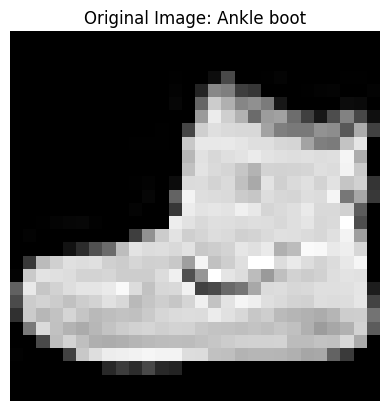

In [8]:
# 2. Display original image BEFORE model building
plt.imshow(x_train[0], cmap='gray')
plt.title("Original Image: " + class_names[y_train[0]])
plt.axis('off')
plt.show()

In [9]:

# 3. Normalize images
x_train = x_train / 255.0
x_test = x_test / 255.0

In [10]:
# 4. Build CNN model
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

In [11]:
# 5. Compile model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])


In [12]:
# 6. Train model
model.fit(x_train, y_train, epochs=5, validation_split=0.1)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 34s 18ms/step - accuracy: 0.8280 - loss: 0.4766 - val_accuracy: 0.8702 - val_loss: 0.3529
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 26s 15ms/step - accuracy: 0.8840 - loss: 0.3220 - val_accuracy: 0.8807 - val_loss: 0.3285
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 28s 17ms/step - accuracy: 0.9009 - loss: 0.2722 - val_accuracy: 0.8947 - val_loss: 0.2772
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 44s 18ms/step - accuracy: 0.9121 - loss: 0.2404 - val_accuracy: 0.9042 - val_loss: 0.2679
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 40s 18ms/step - accuracy: 0.9200 - loss: 0.2161 - val_accuracy: 0.9038 - val_loss: 0.2552


In [13]:

# 7. Evaluate model
loss, accuracy = model.evaluate(x_test, y_test)
print("Test Accuracy:", accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9005 - loss: 0.2711
Test Accuracy: 0.9004999995231628


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 370ms/step


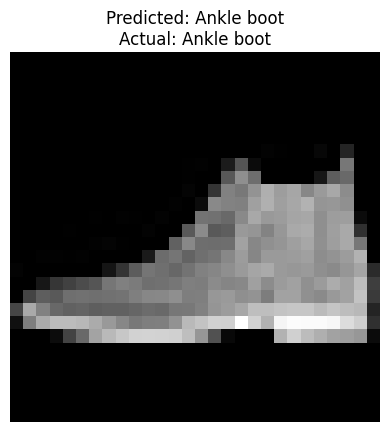

In [14]:

# 8. Display image AFTER model building and training
prediction = model.predict(x_test[:1])
predicted_class = prediction.argmax()

plt.imshow(x_test[0], cmap='gray')
plt.title("Predicted: " + class_names[predicted_class] +
          "\nActual: " + class_names[y_test[0]])
plt.axis('off')
plt.show()




### Q1. What is Fashion MNIST, and what is image classification?

Fashion MNIST is a dataset containing 70,000 grayscale clothing images. It has 60,000 training images and 10,000 testing images. Each image is \\(28 \times 28\\) pixels and belongs to one of 10 classes. Image classification means predicting the category of an image, such as a shirt, shoe, or bag.

### Q2. What is CNN, and why is it used for image classification?

CNN stands for Convolutional Neural Network. It is a deep learning model that automatically extracts features such as edges, shapes, and textures from images. It is preferred over a basic fully connected neural network because it preserves spatial information and can learn image features efficiently.

### Q3. What is preprocessing, and why do we normalize and reshape images?

Preprocessing prepares images for model training. Normalization divides pixel values by 255 to convert them from the range 0–255 to 0–1. Reshaping or adding a channel dimension changes the image shape from `(28, 28)` to `(28, 28, 1)`, which is required by the CNN's convolutional layer.

### Q4. Why do we use `cmap='viridis'` and `interpolation='nearest'`?

`cmap='viridis'` displays grayscale pixel values using different colors. `interpolation='nearest'` prevents smoothing between pixels, making the image appear sharper and pixelated. These settings change only the visualization, not the actual image data used by the model.

### Q5. Explain the architecture of your CNN model.

Our CNN consists of an input layer, two convolutional layers, two max-pooling layers, a flatten layer, a dense hidden layer with 64 neurons, and an output layer with 10 neurons. The convolutional layers extract features, pooling reduces dimensions, flatten converts features into a vector, and dense layers perform classification.

### Q6. What is a convolutional layer, filter, and kernel?

A convolutional layer extracts image features by applying filters to the input image. A filter or kernel is a small matrix that moves across the image and detects patterns. In our code, `Conv2D(32, (3,3))` means the layer uses 32 filters, each of size \\(3 \times 3\\).

### Q7. What is ReLU, and why is it used?

ReLU stands for Rectified Linear Unit. It introduces non-linearity into the network by converting negative values to zero while keeping positive values unchanged.

\\[ f(x)=\max(0,x) \\]

It helps the model learn complex patterns.

### Q8. What is max pooling, and why do we use it?

Max pooling reduces the height and width of feature maps by selecting the maximum value from a small region. For example, `MaxPooling2D((2,2))` uses a \\(2 \times 2\\) window. It reduces computation and retains prominent features.

### Q9. What are Flatten and Dense layers?

The Flatten layer converts multidimensional feature maps into a one-dimensional vector. A Dense layer is fully connected, meaning each neuron connects to all outputs of the previous layer. In our model, `Dense(64)` learns combinations of features before the final classification.

### Q10. Why does the output layer have 10 neurons, and what is softmax?

Fashion MNIST contains 10 classes, so the output layer has 10 neurons. Softmax converts the output scores into probabilities whose sum is 1. The class with the highest probability is selected as the predicted class.

### Q11. What are TensorFlow, Keras, and Sequential?

TensorFlow is an open-source deep learning framework. Keras is its high-level API for building neural networks. `models.Sequential()` creates a model in which layers are arranged one after another in a linear sequence.

### Q12. What are optimizer, loss function, and Adam?

An optimizer updates model weights to reduce prediction errors. A loss function measures the difference between predictions and actual labels. Adam is an adaptive optimization algorithm that adjusts parameter updates using estimates of gradients and their squared values.

### Q13. Why do we use sparse categorical cross-entropy?

We use `sparse_categorical_crossentropy` because our task has 10 classes and the labels are integer values from 0 to 9. It measures the difference between predicted class probabilities and the correct class labels without requiring one-hot encoding.

### Q14. What are epoch, batch size, and validation split?

An epoch is one complete pass through the training dataset. Batch size is the number of images processed before a weight update. In our code, `batch_size=64` means 64 images per batch, while `epochs=5` means five training passes. `validation_split=0.1` reserves 10% of the training data for validation.

### Q15. What are training, validation, and test data?

Training data is used to update the model's weights. Validation data helps monitor performance during training and compare model settings. Test data evaluates the final model on unseen examples. Our dataset contains 60,000 training images and 10,000 test images; the validation split takes 10% of the training data for validation.

### Q16. What are accuracy and loss, and how do we evaluate the model?

Accuracy measures the proportion of correct predictions, while loss measures prediction error according to the selected loss function. We use `model.evaluate(x_test, y_test)` to calculate test loss and test accuracy.

\\[ \text{Accuracy}=\frac{\text{Correct Predictions}}{\text{Total Predictions}}\times100 \\]


### Q17. What do `model.predict()` and `argmax()` do?

`model.predict()` produces class probabilities for the input image. `argmax()` returns the index of the highest probability, giving the predicted class.

For example, if the highest probability is at index 9, the predicted class is `Ankle boot`.

### Q18. What is overfitting, and how can it be prevented?

Overfitting occurs when a model performs well on training data but poorly on unseen data. It can be reduced using dropout, data augmentation, early stopping, regularization, and appropriate model complexity.

### Q19. What is the difference between CNN and a fully connected neural network? Can CNN classify color images?

CNN extracts spatial features using convolutional filters and shares weights across image locations. A fully connected network connects each neuron to all neurons in the previous layer. CNN can classify both grayscale and RGB images: grayscale images have one channel, while RGB images have three channels.

### Q20. What accuracy does your model achieve, and what happens if you change the filters or remove normalization?

A basic CNN may achieve around 90% test accuracy on Fashion MNIST, but the actual accuracy must be obtained from the program output. Increasing the number of filters may help extract more features but increases computation and memory usage. Removing normalization may make training less efficient or stable.

## Quick revision of your code

| Concept              | Value                            |
| -------------------- | -------------------------------- |
| Dataset              | Fashion MNIST                    |
| Image dimensions     | \\(28 \times 28 \times 1\\)      |
| Classes              | 10                               |
| Convolution filters  | 32 and 64                        |
| Kernel size          | \\(3 \times 3\\)                 |
| Pool size            | \\(2 \times 2\\)                 |
| Hidden dense neurons | 64                               |
| Output neurons       | 10                               |
| Activation functions | ReLU and Softmax                 |
| Optimizer            | Adam                             |
| Loss                 | Sparse categorical cross-entropy |
| Epochs               | 5                                |
| Batch size           | 64                               |

Exam tip: If the examiner asks you to explain the complete program, answer in this order: dataset loading → normalization → CNN architecture → compilation → training → evaluation → prediction.